# ToysAD-8K DS1 Proposal and Mask Evaluation

**Notebook file:** `06.1-toysad8k-ds1-proposal-and-mask-evaluation.ipynb`

This notebook evaluates the frozen LocateAnything and SAM 2.1 outputs on the complete DS1 development screen. DS1 contains 100 scenes, 20 views per scene and 2,000 images.

It answers four questions:

1. Does LocateAnything find the expected objects with useful box accuracy?
2. Does SAM 2.1 preserve the objects when prompted by reference boxes?
3. How much quality is lost when SAM uses automatic boxes?
4. Is the detection and segmentation path ready for the next development stage?

This is evaluator-only work. Models have already finished before this notebook opens supplied masks, source crosswalks or protected subgroup fields.

## Saved-output evidence copy

This notebook records the completed run for repository review. Its code and markdown match the clean runnable notebook. Private scene visuals and identifier-bearing output were removed. Safe aggregate tables and charts were retained.

Run stage: `06.1 DS1 proposal and mask evaluation`  
Clean notebook SHA-256: `c99ea280caf24faeda03c61f3a96ce274fe6bffc89bf0162daa8473d576fee15`  
Downloaded saved-output SHA-256: `142deac2d8d587de708b5a5b4b5930d399eb92bebf18885afd575616422b26c0`


## Evaluation boundary

The notebook reads three immutable inputs: the private DS1 evaluator package, the complete LocateAnything output and the complete SAM output. Before any metric is calculated, it verifies both model run records, both artifact manifests, the evaluator crosswalk, every prompt box, every RGB hash and the full upstream hash chain. It does not rerun either model and does not change predictions after seeing the labels.

Detailed object records stay under `private`. GitHub and ClearML receive aggregate tables, charts, hashes and the component decision. A separate `model_input` folder contains the supplied-mask, reference-box and automatic-box routes without source IDs, labels, roles, anomaly fields or protected ordering.

In [1]:
from __future__ import annotations

import json
import os
from hashlib import sha256
from pathlib import Path
import subprocess
import sys

from IPython.display import Image as DisplayImage, display
import pandas as pd

sys.dont_write_bytecode = True

NOTEBOOK_NAME = "06.1-toysad8k-ds1-proposal-and-mask-evaluation.ipynb"
ENVIRONMENT = "kaggle" if Path("/kaggle/working").is_dir() else "local"


def find_code_root() -> Path:
    configured = os.getenv("VPI_CODE_ROOT")
    candidates = [Path(configured).expanduser()] if configured else []
    candidates.extend([Path.cwd(), *Path.cwd().parents])
    if Path("/kaggle/input").is_dir():
        candidates.extend(path.parents[3] for path in Path("/kaggle/input").rglob("mask_evaluation_ds1.py"))
    for candidate in candidates:
        marker = candidate / "src" / "visual_peer_inspector" / "workflows" / "mask_evaluation_ds1.py"
        if marker.is_file():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the Notebook 06.1 code snapshot")


CODE_ROOT = find_code_root()
sys.path.insert(0, str(CODE_ROOT / "src"))
from visual_peer_inspector.verification import verify_code_snapshot_record

snapshot_path = CODE_ROOT / "snapshot_record.json"
snapshot = verify_code_snapshot_record(CODE_ROOT, snapshot_path)
print(f"Environment: {ENVIRONMENT}")
print(f"Notebook: {NOTEBOOK_NAME}")
print(f"Code snapshot: {snapshot['snapshot_sha256']}")

Environment: kaggle
Notebook: 06.1-toysad8k-ds1-proposal-and-mask-evaluation.ipynb
Code snapshot: cfb8559faba4745dd1d29c0148ed26ec985500009c0f69f127b4d771bfaa45ca


## Input paths and frozen settings

Attach the evaluator package and the downloaded outputs from Notebooks 04.1 and 05.1 as private Kaggle datasets. Each input is found through a unique internal marker rather than a mutable folder name. Bootstrap intervals resample the frozen base-asset clusters and keep every view in its sampled cluster.

In [2]:
def find_one(pattern: str, required_file: str) -> Path:
    configured = os.getenv(pattern)
    if configured:
        root = Path(configured).expanduser().resolve()
        if not (root / required_file).is_file() and not (root / "private" / required_file).is_file():
            raise FileNotFoundError(f"Configured input does not contain {required_file}")
        return root
    search_root = Path("/kaggle/input") if ENVIRONMENT == "kaggle" else CODE_ROOT
    candidates = set()
    for path in search_root.rglob(required_file):
        candidates.add(path.parent.parent if path.parent.name == "private" else path.parent)
    if len(candidates) != 1:
        raise FileNotFoundError(f"Expected one input containing {required_file}, found {len(candidates)}")
    return candidates.pop().resolve()


EVALUATOR_ROOT = find_one("VPI_DS1_EVALUATOR_ROOT", "evaluator_crosswalk.jsonl")
PROPOSAL_ROOT = find_one("VPI_DS1_PROPOSAL_ROOT", "proposal_results.jsonl")
SAM_ROOT = find_one("VPI_DS1_SAM_ROOT", "mask_results.jsonl")
OUTPUT_ROOT = Path("/kaggle/working/toysad8k_ds1_mask_evaluation" if ENVIRONMENT == "kaggle" else "outputs/toysad8k_ds1_mask_evaluation").resolve()
BOOTSTRAP_REPETITIONS = int(os.getenv("VPI_BOOTSTRAP_REPETITIONS", "10000"))
BOOTSTRAP_SEED = 32040

paths = pd.DataFrame([
    {"input": "private evaluator package", "folder": EVALUATOR_ROOT.name},
    {"input": "LocateAnything output", "folder": PROPOSAL_ROOT.name},
    {"input": "SAM 2.1 output", "folder": SAM_ROOT.name},
])
display(paths)

,input,folder
0,private evaluator package,vpi-toysad-ds1-mask-evaluator
1,LocateAnything output,vpi-toysad-ds1-locateanything-output
2,SAM 2.1 output,toysad8k_ds1_sam21_segmentation


## Run the frozen evaluator

The workflow checks all input coverage and upstream identities before calculating metrics. Proposal matching uses one-to-one assignment at box IoU 0.50. Mask quality reports IoU, Dice, boundary F1, detection-aware recall at mask IoU 0.75 and detection-aware mean IoU. Misses, extras, merge candidates and split candidates remain in the denominator.

In [3]:
from visual_peer_inspector.workflows.mask_evaluation_ds1 import run_ds1_mask_evaluation

snapshot_versions = snapshot.get("platform_versions", {})


def required_version(key: str) -> str:
    value = os.getenv(f"VPI_{key.upper()}") or snapshot_versions.get(key)
    if not value or str(value).strip().lower() in {"pending", "unknown", "unavailable"}:
        raise RuntimeError(f"The code snapshot is missing version pin: {key}")
    return str(value)


notebook_path = CODE_ROOT / (
    "notebooks/detection-and-segmentation/toysad8k-ds1-mask-evaluation/"
    "06.1-toysad8k-ds1-proposal-and-mask-evaluation.ipynb"
)
if not notebook_path.is_file():
    raise FileNotFoundError("The code snapshot does not contain the exact Notebook 06.1 source")
provenance = {
    "notebook_name": NOTEBOOK_NAME,
    "execution_environment": ENVIRONMENT,
    "git_commit": snapshot["git_commit"],
    "git_dirty": snapshot["git_dirty"],
    "precommit_candidate": snapshot["precommit_candidate"],
    "snapshot_sha256": snapshot["snapshot_sha256"],
    "notebook_sha256": sha256(notebook_path.read_bytes()).hexdigest(),
    "code_dataset_version": required_version("code_dataset_version"),
    "kaggle_notebook_version_06_1": required_version("kaggle_notebook_version_06_1"),
}

run_record = run_ds1_mask_evaluation(
    evaluator_root=EVALUATOR_ROOT,
    proposal_output_root=PROPOSAL_ROOT,
    sam_output_root=SAM_ROOT,
    output_root=OUTPUT_ROOT,
    evaluator_provenance=provenance,
    bootstrap_repetitions=BOOTSTRAP_REPETITIONS,
    bootstrap_seed=BOOTSTRAP_SEED,
)
display(pd.DataFrame([run_record["coverage"]]))

,reference_rows,decoded_sam_masks,proposal_images,sam_images
0,7700,16949,2000,2000


## Proposal metrics

,metric,value
0,image_count,2000.000000
1,scene_count,100.000000
2,reference_count,7700.000000
3,proposal_count,9249.000000
4,matched_count_at_0_25,7362.000000
5,matched_count_at_0_50,7276.000000
6,matched_count_at_0_75,6960.000000
7,exact_count_rate,0.900500
8,count_mean_absolute_error,0.992500
9,count_signed_bias,0.774500


,metric,point_estimate,ci_lower_95,ci_upper_95,bootstrap_repetitions,asset_cluster_count,seed
0,exact_count_rate,0.900500,0.863861,0.935149,10000,27,32040
1,micro_precision_at_0_50,0.786680,0.657874,0.929500,10000,27,32040
2,micro_recall_at_0_50,0.944935,0.922800,0.965658,10000,27,32040
3,micro_recall_at_0_75,0.903896,0.869693,0.936352,10000,27,32040
4,mean_matched_iou,0.935728,0.922658,0.947455,10000,27,32040
5,detection_aware_mean_iou,0.884202,0.857530,0.910169,10000,27,32040
6,full_image_success_rate,0.882500,0.838835,0.923980,10000,27,32040


,dimension,subgroup_count
0,anomaly_family,8
1,category,27
2,object_count,3
3,view_id,20


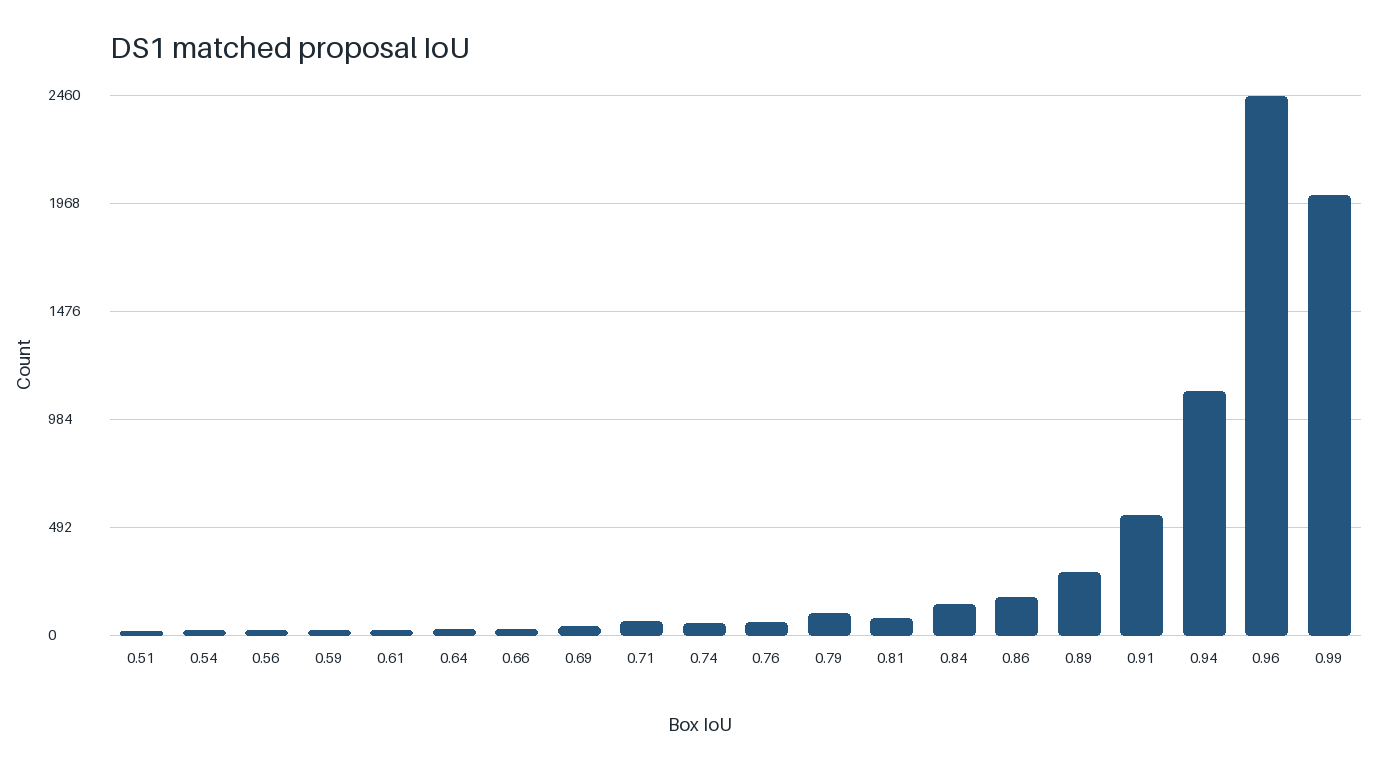

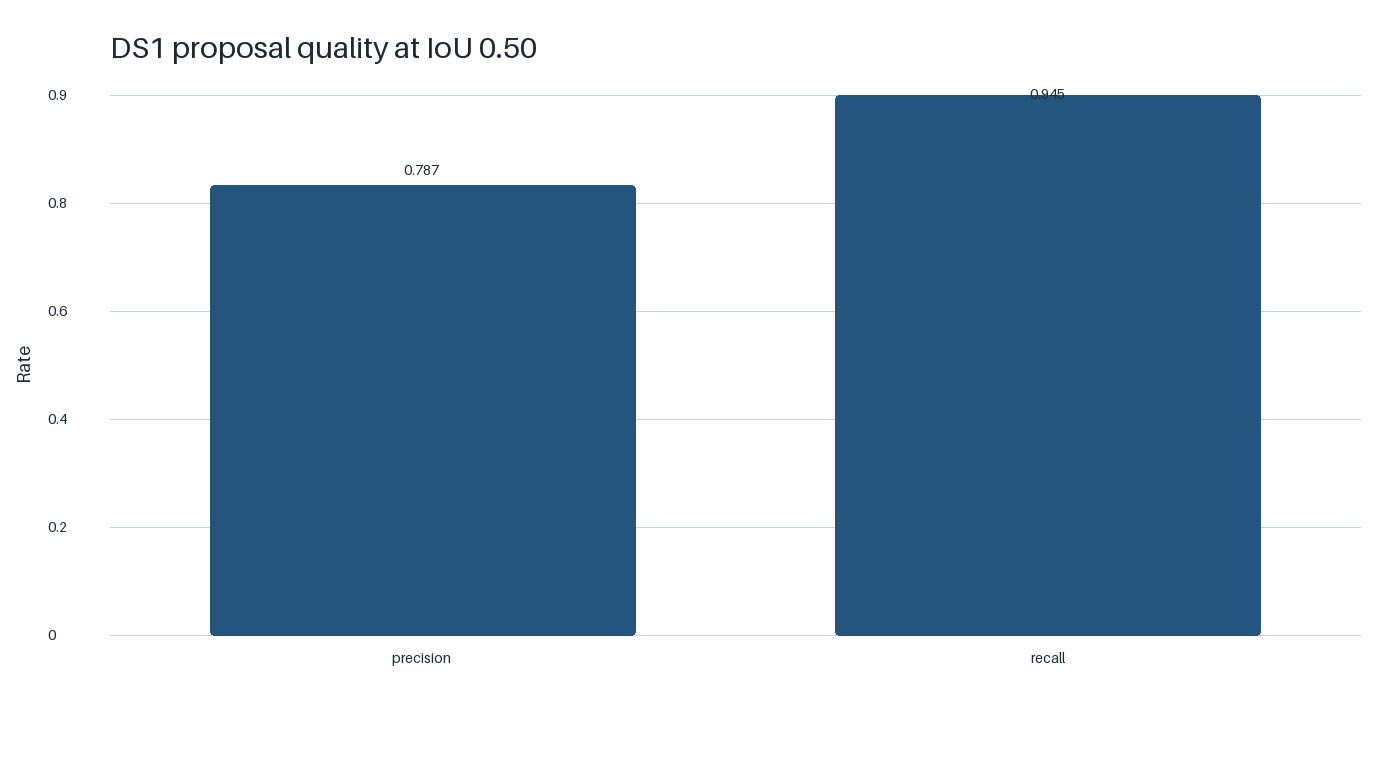

In [4]:
proposal_summary = pd.read_csv(OUTPUT_ROOT / "safe" / "proposal_summary.csv")
proposal_subgroups = pd.read_csv(OUTPUT_ROOT / "safe" / "proposal_subgroups.csv")
proposal_intervals = pd.read_csv(OUTPUT_ROOT / "safe" / "proposal_bootstrap_intervals.csv")
display(proposal_summary)
display(proposal_intervals)
display(proposal_subgroups.groupby("dimension", as_index=False)["value"].count().rename(columns={"value": "subgroup_count"}))
display(DisplayImage(filename=str(OUTPUT_ROOT / "safe" / "proposal_matched_iou_distribution.png")))
display(DisplayImage(filename=str(OUTPUT_ROOT / "safe" / "proposal_precision_recall.png")))

## Mask-route metrics

,route,reference_count,prediction_count,matched_reference_count,missed_reference_count,unmatched_prediction_count,detection_aware_recall_at_0_75,mean_matched_iou,detection_aware_mean_iou,mean_matched_dice,...,mean_matched_boundary_f1,mean_matched_boundary_precision,mean_matched_boundary_recall,detection_aware_mean_boundary_f1,detection_aware_mean_boundary_precision,detection_aware_mean_boundary_recall,mean_prediction_spill_fraction,prediction_spill_rate,mask_iou_threshold,boundary_tolerance_pixels
0,automatic_box,7700,9249,7276,424,1973,0.924805,0.945971,0.893881,0.970747,...,0.976651,0.976403,0.980912,0.922871,0.922638,0.926899,0.041193,0.488161,0.75,3
1,reference_box,7700,7700,7700,0,0,0.992338,0.952675,0.952675,0.975121,...,0.985153,0.982166,0.990643,0.985153,0.982166,0.990643,0.000639,0.242987,0.75,3


,metric,direction,scene_count,cluster_count,baseline_mean,candidate_mean,mean_difference,confidence_level,ci_lower,ci_upper,repetitions,seed
0,reference_minus_automatic_iou,baseline_minus_candidate,100,27,0.953458,0.893841,0.059617,0.95,0.037023,0.085088,10000,32040
1,reference_minus_automatic_dice,baseline_minus_candidate,100,27,0.975503,0.916748,0.058754,0.95,0.035991,0.084096,10000,32040
2,reference_minus_automatic_boundary_f1,baseline_minus_candidate,100,27,0.983571,0.920450,0.063121,0.95,0.039983,0.088323,10000,32040


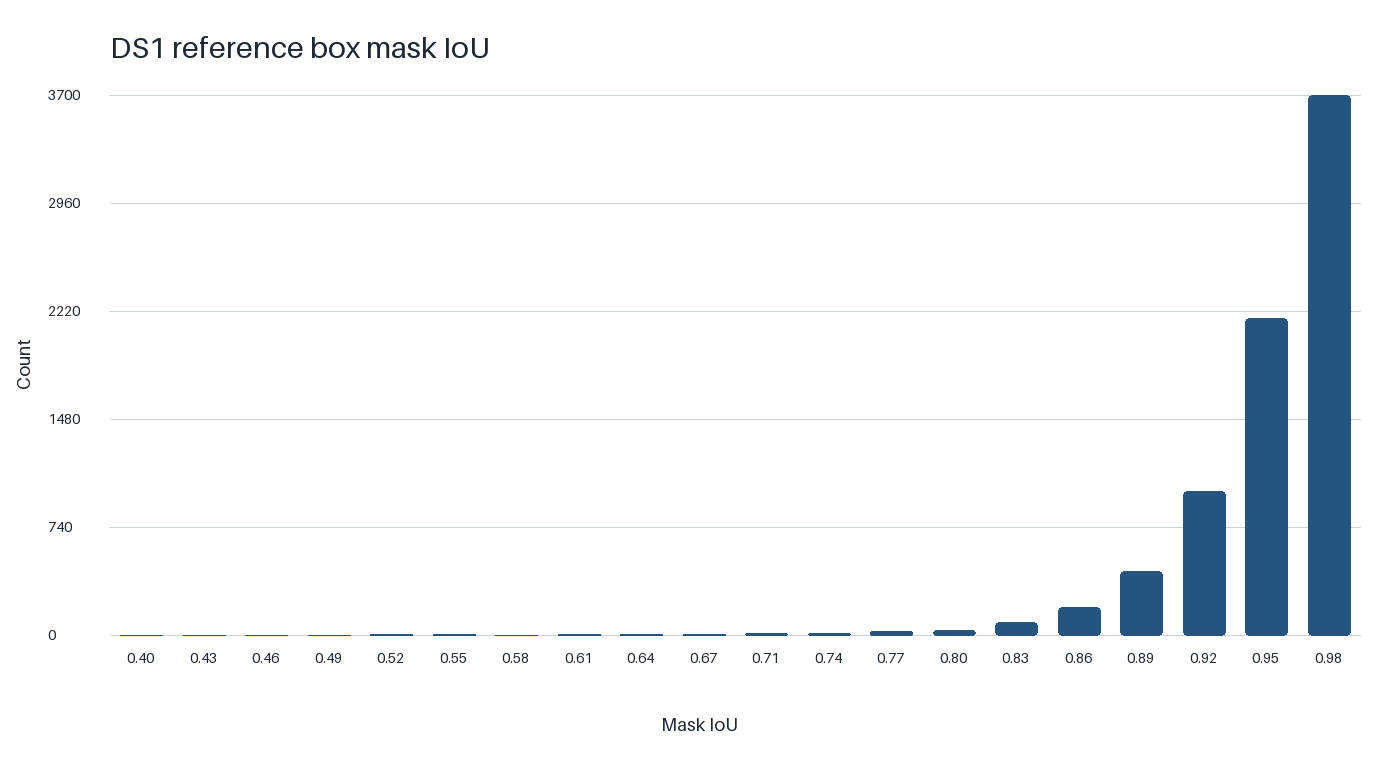

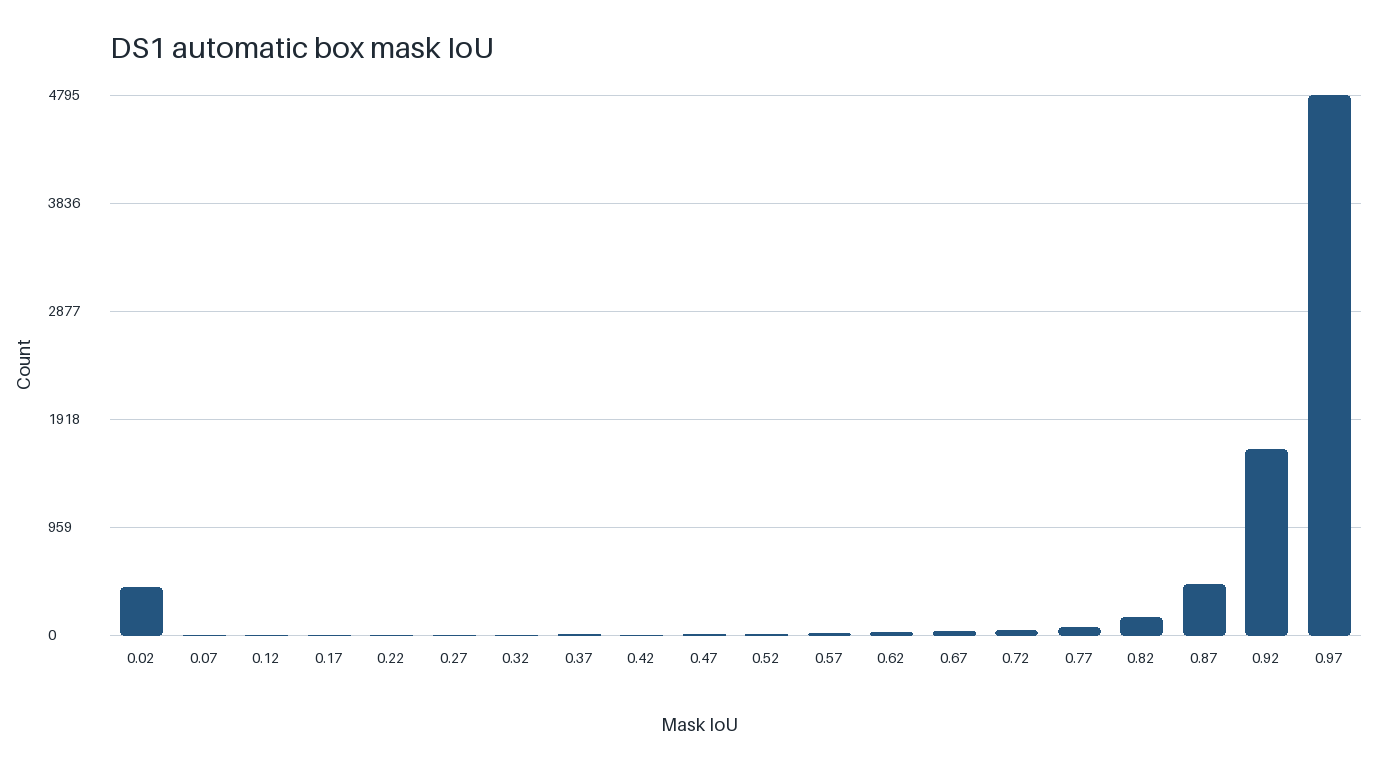

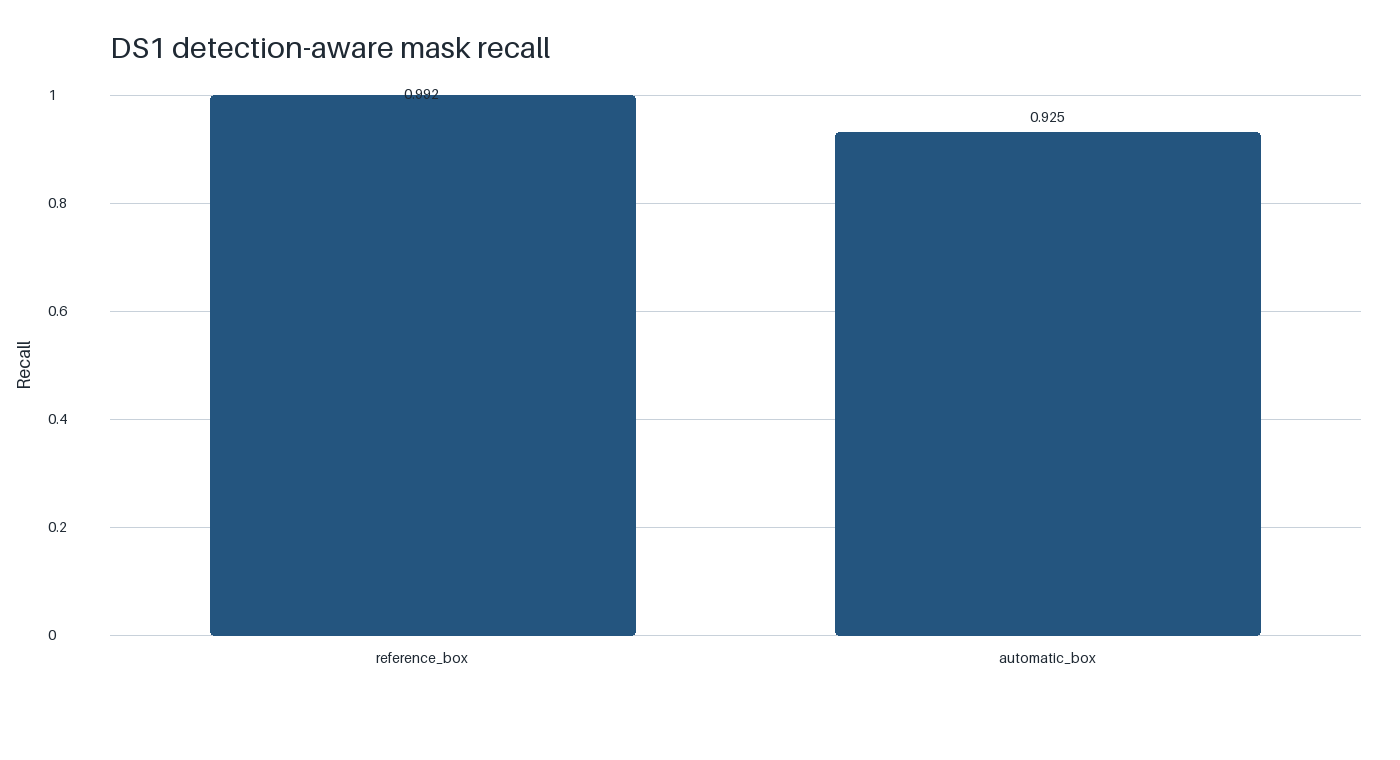

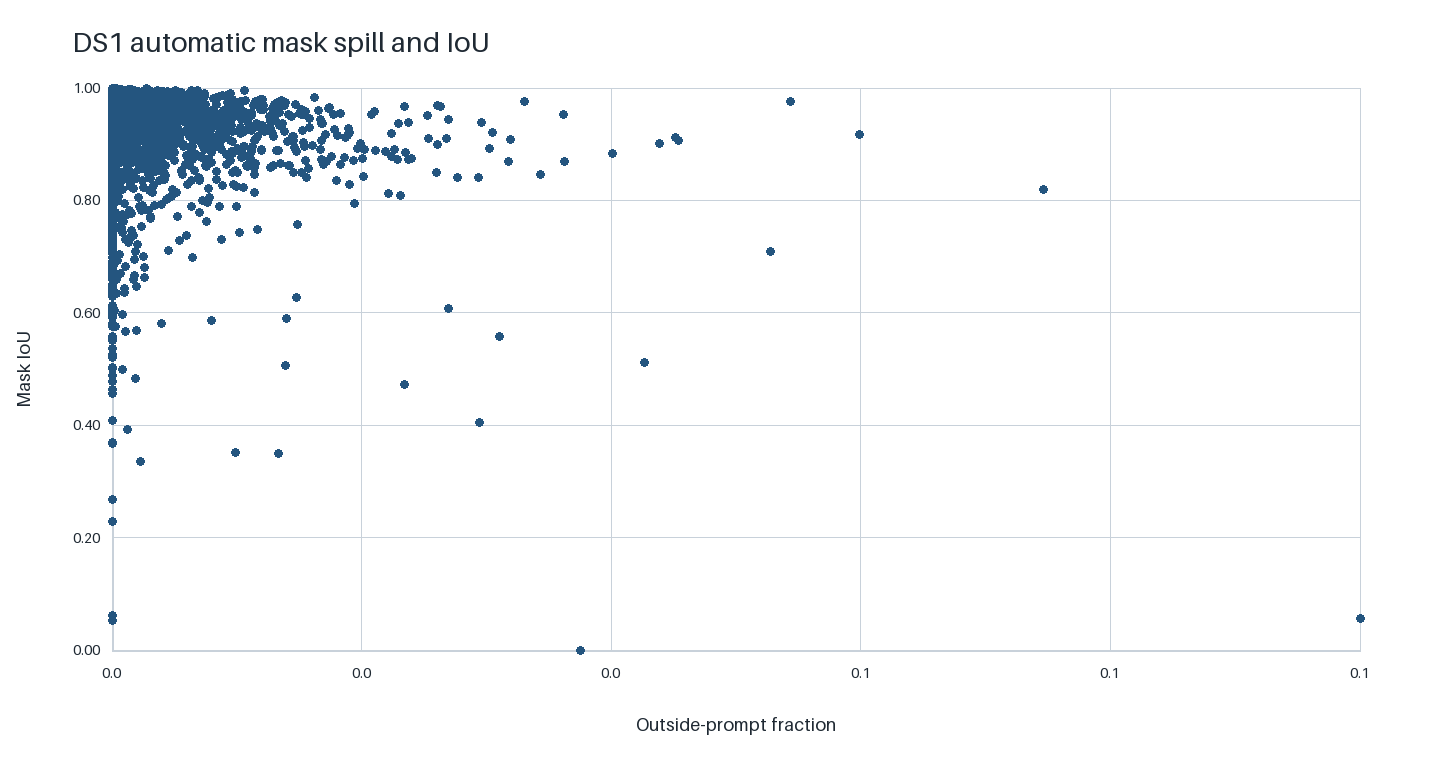

,component,metric,dimension,value,point_estimate,ci_lower_95,cluster_count,scene_count,support_count,support_unit,gate_statistic,gate_observed,threshold,status
0,automatic_box,detection_aware_mean_iou,view_id,V09,0.841555,0.763455,27,100,385,references,ci_lower_95,0.763455,0.80,fail
1,automatic_box,detection_aware_recall_at_0_75,view_id,V09,0.872727,0.791207,27,100,385,references,ci_lower_95,0.791207,0.80,fail
2,proposal,precision_at_0_50,view_id,V09,0.390661,0.200121,27,100,878,proposals,ci_lower_95,0.200121,0.80,fail
3,proposal,recall_at_0_50,view_id,V09,0.890909,0.807975,27,100,385,references,ci_lower_95,0.807975,0.85,fail
4,reference_box,detection_aware_mean_iou,anomaly_family,disc,0.941048,0.918245,9,27,2120,references,ci_lower_95,0.918245,0.80,pass
5,reference_box,detection_aware_recall_at_0_75,anomaly_family,crack,0.983945,0.957851,10,29,2180,references,ci_lower_95,0.957851,0.80,pass


,component,metric,eligible,size
0,automatic_box,detection_aware_mean_iou,no,32
1,automatic_box,detection_aware_mean_iou,yes,26
2,automatic_box,detection_aware_recall_at_0_75,no,32
3,automatic_box,detection_aware_recall_at_0_75,yes,26
4,proposal,precision_at_0_50,no,32
5,proposal,precision_at_0_50,yes,26
6,proposal,recall_at_0_50,no,32
7,proposal,recall_at_0_50,yes,26
8,reference_box,detection_aware_mean_iou,no,32
9,reference_box,detection_aware_mean_iou,yes,26


In [5]:
mask_summary = pd.read_csv(OUTPUT_ROOT / "safe" / "mask_route_summary.csv")
mask_intervals = pd.read_csv(OUTPUT_ROOT / "safe" / "mask_bootstrap_intervals.csv")
display(mask_summary)
display(mask_intervals)
display(DisplayImage(filename=str(OUTPUT_ROOT / "safe" / "reference_box_mask_iou_distribution.png")))
display(DisplayImage(filename=str(OUTPUT_ROOT / "safe" / "automatic_box_mask_iou_distribution.png")))
display(DisplayImage(filename=str(OUTPUT_ROOT / "safe" / "mask_recall_by_route.png")))
display(DisplayImage(filename=str(OUTPUT_ROOT / "safe" / "automatic_spill_vs_mask_iou.png")))
subgroup_intervals = pd.read_csv(OUTPUT_ROOT / "safe" / "subgroup_bootstrap_intervals.csv")
worst_subgroups = pd.read_csv(OUTPUT_ROOT / "safe" / "worst_subgroup_summary.csv")
display(worst_subgroups)
display(subgroup_intervals.groupby(["component", "metric", "eligible"], as_index=False).size())

## Private qualitative diagnostics

The evaluator deterministically selects a representative image, the lowest automatic-route image and the largest reference-versus-automatic route gap. Each panel compares the supplied mask, reference-box SAM mask and automatic-box SAM mask. Green is missed reference area, pink is extra prediction area and white is overlap. These panels stay in the private output and are never sent to ClearML or GitHub.

In [6]:
for diagnostic_kind in ("representative", "worst", "outlier"):
    display(DisplayImage(filename=str(OUTPUT_ROOT / "private" / f"{diagnostic_kind}_mask_panel.png")))

<IPython.core.display.Image object>

<IPython.core.display.Image object>

<IPython.core.display.Image object>

## Runtime, failures and component decision

In [7]:
decision_gates = pd.read_csv(OUTPUT_ROOT / "safe" / "decision_gates.csv")
failures = pd.read_csv(OUTPUT_ROOT / "safe" / "failure_summary.csv")
runtime = json.loads((OUTPUT_ROOT / "safe" / "runtime_summary.json").read_text())
display(decision_gates)
display(failures)
display(pd.DataFrame([runtime]))
display(pd.read_csv(OUTPUT_ROOT / "safe" / "diagnostic_summary.csv"))
print(json.dumps(run_record["component_decision"], indent=2))

,gate,observed,threshold,status
0,proposal precision at 0.50,0.786680,0.90,fail
1,proposal recall at 0.50,0.944935,0.95,fail
2,reference mask recall at 0.75,0.992338,0.90,pass
3,reference detection-aware mean mask IoU,0.952675,0.90,pass
4,automatic mask recall at 0.75,0.924805,0.90,pass
5,automatic detection-aware mean mask IoU,0.893881,0.90,fail
6,automatic_box worst supported subgroup detecti...,0.763455,0.80,fail
7,automatic_box worst supported subgroup detecti...,0.791207,0.80,fail
8,proposal worst supported subgroup precision_at...,0.200121,0.80,fail
9,proposal worst supported subgroup recall_at_0_...,0.807975,0.85,fail


,failure_type,count
0,background_extra,1660
1,complete_miss,243
2,merge_candidate,93
3,split_or_duplicate_candidate,81
4,weak_localisation_extra,232
5,weak_localisation_miss,88


,evaluator_seconds,proposal_median_seconds_per_image,proposal_p95_seconds_per_image,proposal_total_seconds,sam_median_seconds_per_image,sam_p95_seconds_per_image,sam_total_seconds
0,396.918742,0.4119,0.62776,1059.5058,0.251482,0.26024,508.779031


,diagnostic_kind,route,reference_count,prediction_count,miss_count,extra_count,detection_aware_mean_iou
0,representative,reference_box,4,4,0,0,0.962120
1,representative,automatic_box,4,4,0,0,0.959647
2,worst,reference_box,4,4,0,0,0.972623
3,worst,automatic_box,4,1,4,1,0.000000
4,outlier,reference_box,3,3,0,0,0.989607
5,outlier,automatic_box,3,1,3,1,0.000000


{
  "status": "refine_or_replace_locateanything",
  "all_gates_passed": false,
  "final_acceptance": false,
  "reason": "DS1 is a development screen. The component result must be confirmed on the locked internal and official evaluation roles."
}


## Bounded ClearML finalisation

Tracking starts only after evaluator compute and artifact manifests have finished. The finaliser verifies the complete aggregate allowlist before it reads ClearML credentials. Kaggle Secrets are loaded only inside that isolated subprocess. The child uses the official ClearML hosts and retries only transient task-creation connection failures. Its receipt stores sanitized categories and retry counts without exception text. Tracking failure does not remove or invalidate the completed evaluation outputs.

In [8]:
tracking_receipt = OUTPUT_ROOT / "tracking_receipt.json"
tracking_result = {"status": "not_started", "clearml_task_id": None}
tracking_environment = os.environ.copy()
existing_pythonpath = tracking_environment.get("PYTHONPATH")
tracking_environment["PYTHONPATH"] = str(CODE_ROOT / "src") + (
    os.pathsep + existing_pythonpath if existing_pythonpath else ""
)
try:
    subprocess.run(
        [
            sys.executable,
            str(CODE_ROOT / "scripts/finalize_ds1_mask_evaluation_clearml.py"),
            "--safe-root",
            str(OUTPUT_ROOT / "safe"),
            "--receipt",
            str(tracking_receipt),
            "--mode",
            "online",
            "--secret-source",
            "kaggle" if ENVIRONMENT == "kaggle" else "environment",
            "--wall-time-seconds",
            "180",
            "--tag",
            "candidate",
            "--tag",
            "notebook-06.1",
            "--tag",
            "ds1",
            "--tag",
            "locateanything",
            "--tag",
            "sam2.1",
            "--tag",
            "evaluation",
            "--tag",
            "kaggle",
            "--tag",
            "full",
        ],
        env=tracking_environment,
        text=True,
        capture_output=True,
        timeout=240,
        check=True,
    )
    tracking_result = json.loads(tracking_receipt.read_text(encoding="utf-8"))
except Exception as error:
    tracking_result = {
        "schema_version": 1,
        "status": "failed",
        "tracking_mode": "online",
        "clearml_task_id": None,
        "error_type": type(error).__name__,
    }
    tracking_receipt.write_text(
        json.dumps(tracking_result, indent=2, sort_keys=True) + "\n",
        encoding="utf-8",
    )
display(tracking_result)

{'clearml_hosts': {'CLEARML_API_HOST': 'https://api.clear.ml',
  'CLEARML_FILES_HOST': 'https://files.clear.ml',
  'CLEARML_WEB_HOST': 'https://app.clear.ml'},
 'clearml_task_id': None,
 'component_decision': 'refine_or_replace_locateanything',
 'offline_session_folder': None,
 'project': 'Visual Peer Inspector/02 Detection and Segmentation',
 'run_status': 'completed',
 'safe_manifest_sha256': '498303d29229466a60d740c4c30e2f14922836fafe30ef033883849e1c4c5365',
 'schema_version': 1,
 'snapshot_sha256': 'cfb8559faba4745dd1d29c0148ed26ec985500009c0f69f127b4d771bfaa45ca',
 'stage': 'notebook_06_1_clearml_finalisation',
 'status': 'failed',
 'task_name': 'ds1-proposal-mask-evaluation-kaggle-candidate',
 'tracking_attempt_count': 0,
 'tracking_error_category': 'internal_error',
 'tracking_error_type': 'ConnectionError',
 'tracking_mode': 'online',
 'tracking_retry_count': 0,
 'tracking_transient_failure_count': 0}

## Outputs and next use

The `safe` folder contains the report and ClearML evidence. The `private` folder contains evaluator-only object records and must not be committed or uploaded to ClearML. The `model_input` folder is the verified label-free three-route package for Vaibhav's representation pipeline.

The DS1 decision is a development-stage component decision. It does not replace evaluation on the locked internal role or the final official test role.

In [9]:
final_summary = {
    "status": run_record["status"],
    "scenes": run_record["cohort"]["scene_count"],
    "images": run_record["coverage"]["sam_images"],
    "component_decision": run_record["component_decision"]["status"],
    "all_component_gates_passed": run_record["component_decision"]["all_gates_passed"],
    "tracking_status": tracking_result["status"],
    "clearml_task_id": tracking_result.get("clearml_task_id"),
    "snapshot_sha256": snapshot["snapshot_sha256"],
}
display(final_summary)
if run_record["status"] != "completed":
    raise RuntimeError("Notebook 06.1 evaluation did not complete")

{'status': 'completed',
 'scenes': 100,
 'images': 2000,
 'component_decision': 'refine_or_replace_locateanything',
 'all_component_gates_passed': False,
 'tracking_status': 'failed',
 'clearml_task_id': None,
 'snapshot_sha256': 'cfb8559faba4745dd1d29c0148ed26ec985500009c0f69f127b4d771bfaa45ca'}